# ทำนายผลผลิตทุเรียนด้วย Ridge + VPD
ข้อมูลปี 2010-2025; ทดสอบปี 2017-2025 แบบ chronological rolling. กันปี test ออกจากการเทรนในแต่ละ fold แต่ไม่ใช่ชุดยืนยันอิสระจากการเลือกกลุ่มโมเดล. โค้ดเต็มแยกตามขั้นใน `tools/durian_model/`. รันทุก cell ตามลำดับ.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tools/durian_model').is_dir())
sys.path.insert(0, str(ROOT / 'tools/durian_model'))
from common import OUT


## ขั้น 0: step0_audit_data
ตรวจ key, target ต่อพื้นที่ให้ผล, ปี และ source hash ก่อนใช้ข้อมูล

In [2]:
import step0_audit_data
result_0 = step0_audit_data.run()
result_0

Step 0: validated 80 province-years; target uses bearing area.


{'panel_years': [2010, 2025],
 'rows': 80,
 'provinces': ['22', '33', '53', '84', '86'],
 'target': 'production_tonnes * 1000 / bearing_rai',
 'lag_source': '2009-2024 actual annual yield, not the current-year target',
 'input_sha256': {'production_annual.csv': 'c5eed63bddcb777afcbf4bb04e9f25cccdbf08d758636136a96730c884655b73',
  'harvest_monthly.csv': 'a1a04a1bcd4e37d1640a76a3fb733221563fcb5b00a43f6ce2046760bff7f739',
  'weather_daily.csv': '28dfcab00a24086735a7a8b596a19c52334a5025a7c3abb0297ff2a663d21054'},
 'unit': 'province-year, kg/rai',
 'reason_for_period': 'Calendar-based recent-year focus; no low-yield rows removed',
 'source_edition': 'Local OAE XLSX: years 2540-2568, data_date 2026-07-14; catalog year metadata differs',
 'finality': 'Recorded official snapshot, not synthetic labels. Final-versus-estimate status is not explicitly encoded per row; not independently reconfirmed for every year.',
 'limits': ['Retrospectively revised records; publication vintages not reconstructe

## ขั้น 1: step1_split_years
ทดสอบปีถัดไป และ tune ด้วย 3 ปีก่อนหน้าเท่านั้น ไม่สุ่มข้ามเวลา

In [3]:
import step1_split_years
result_1 = step1_split_years.run()
result_1

Step 1: 9 outer test years, 45 test province-years; no random shuffle.


[{'test_year': 2017,
  'train_start': 2010,
  'train_end': 2016,
  'inner_validation_years': [2014, 2015, 2016]},
 {'test_year': 2018,
  'train_start': 2010,
  'train_end': 2017,
  'inner_validation_years': [2015, 2016, 2017]},
 {'test_year': 2019,
  'train_start': 2010,
  'train_end': 2018,
  'inner_validation_years': [2016, 2017, 2018]},
 {'test_year': 2020,
  'train_start': 2010,
  'train_end': 2019,
  'inner_validation_years': [2017, 2018, 2019]},
 {'test_year': 2021,
  'train_start': 2010,
  'train_end': 2020,
  'inner_validation_years': [2018, 2019, 2020]},
 {'test_year': 2022,
  'train_start': 2010,
  'train_end': 2021,
  'inner_validation_years': [2019, 2020, 2021]},
 {'test_year': 2023,
  'train_start': 2010,
  'train_end': 2022,
  'inner_validation_years': [2020, 2021, 2022]},
 {'test_year': 2024,
  'train_start': 2010,
  'train_end': 2023,
  'inner_validation_years': [2021, 2022, 2023]},
 {'test_year': 2025,
  'train_start': 2010,
  'train_end': 2024,
  'inner_validation_yea

## ขั้น 2: step2_process_data
เลือกฤดูเฉพาะจากปี train สร้างช่วงอายุผลและ daily VPD proxy ไม่เติมค่าหายเป็นศูนย์

In [4]:
import step2_process_data
result_2 = step2_process_data.run()
result_2

Step 2: 4160 feature rows; only 80 independent annual targets.


{'feature_rows': 4160,
 'independent_targets': 80,
 'features': ['previous_yield_kg_rai',
  'pre_bloom_90d_rain_mm',
  'fruit_0_29d_rain_mm',
  'fruit_30_59d_rain_mm',
  'fruit_60_89d_solar_mj_m2_day',
  'fruit_90_to_harvest_temperature_c',
  'vpd_pre_bloom_mean_kpa',
  'vpd_early_fruit_p90_kpa']}

## ขั้น 3: step3_train_model
เลือกอายุ 4 ค่าและ alpha 3 ค่าเฉพาะ inner validation แล้ว refit ด้วยปีอดีต

In [5]:
import step3_train_model
result_3 = step3_train_model.run()
result_3

Step 3: train through 2016, age=140, alpha=10.0


Step 3: train through 2017, age=130, alpha=100.0


Step 3: train through 2018, age=120, alpha=100.0


Step 3: train through 2019, age=120, alpha=1.0


Step 3: train through 2020, age=150, alpha=1.0


...

Step 3: train through 2022, age=150, alpha=1.0


Step 3: train through 2023, age=140, alpha=1.0


Step 3: train through 2024, age=140, alpha=1.0


Step 3: train through 2025, age=140, alpha=1.0


{'folds': 9,
 'test_rows': 45,
 'final_train_end': 2025,
 'final_age': 140,
 'final_alpha': 1.0}

## ขั้น 4: step4_investigate_feature_importance
ดู signed standardized coefficients ไม่ใช่หลักฐานเชิงสาเหตุ

Step 4: saved standardized coefficients; correlated inputs can share effects.


,feature,coefficient_kg_rai_per_training_sd,absolute_coefficient
8,fruit_0_29d_rain_mm,-196.337080,196.337080
9,fruit_30_59d_rain_mm,169.668331,169.668331
6,previous_yield_kg_rai,168.278881,168.278881
2,province_53,-157.887279,157.887279
11,fruit_90_to_harvest_temperature_c,-145.105964,145.105964
0,province_22,126.132009,126.132009
1,province_33,104.351173,104.351173
5,year_ce,79.947078,79.947078
10,fruit_60_89d_solar_mj_m2_day,68.736210,68.736210
12,vpd_pre_bloom_mean_kpa,-55.883313,55.883313


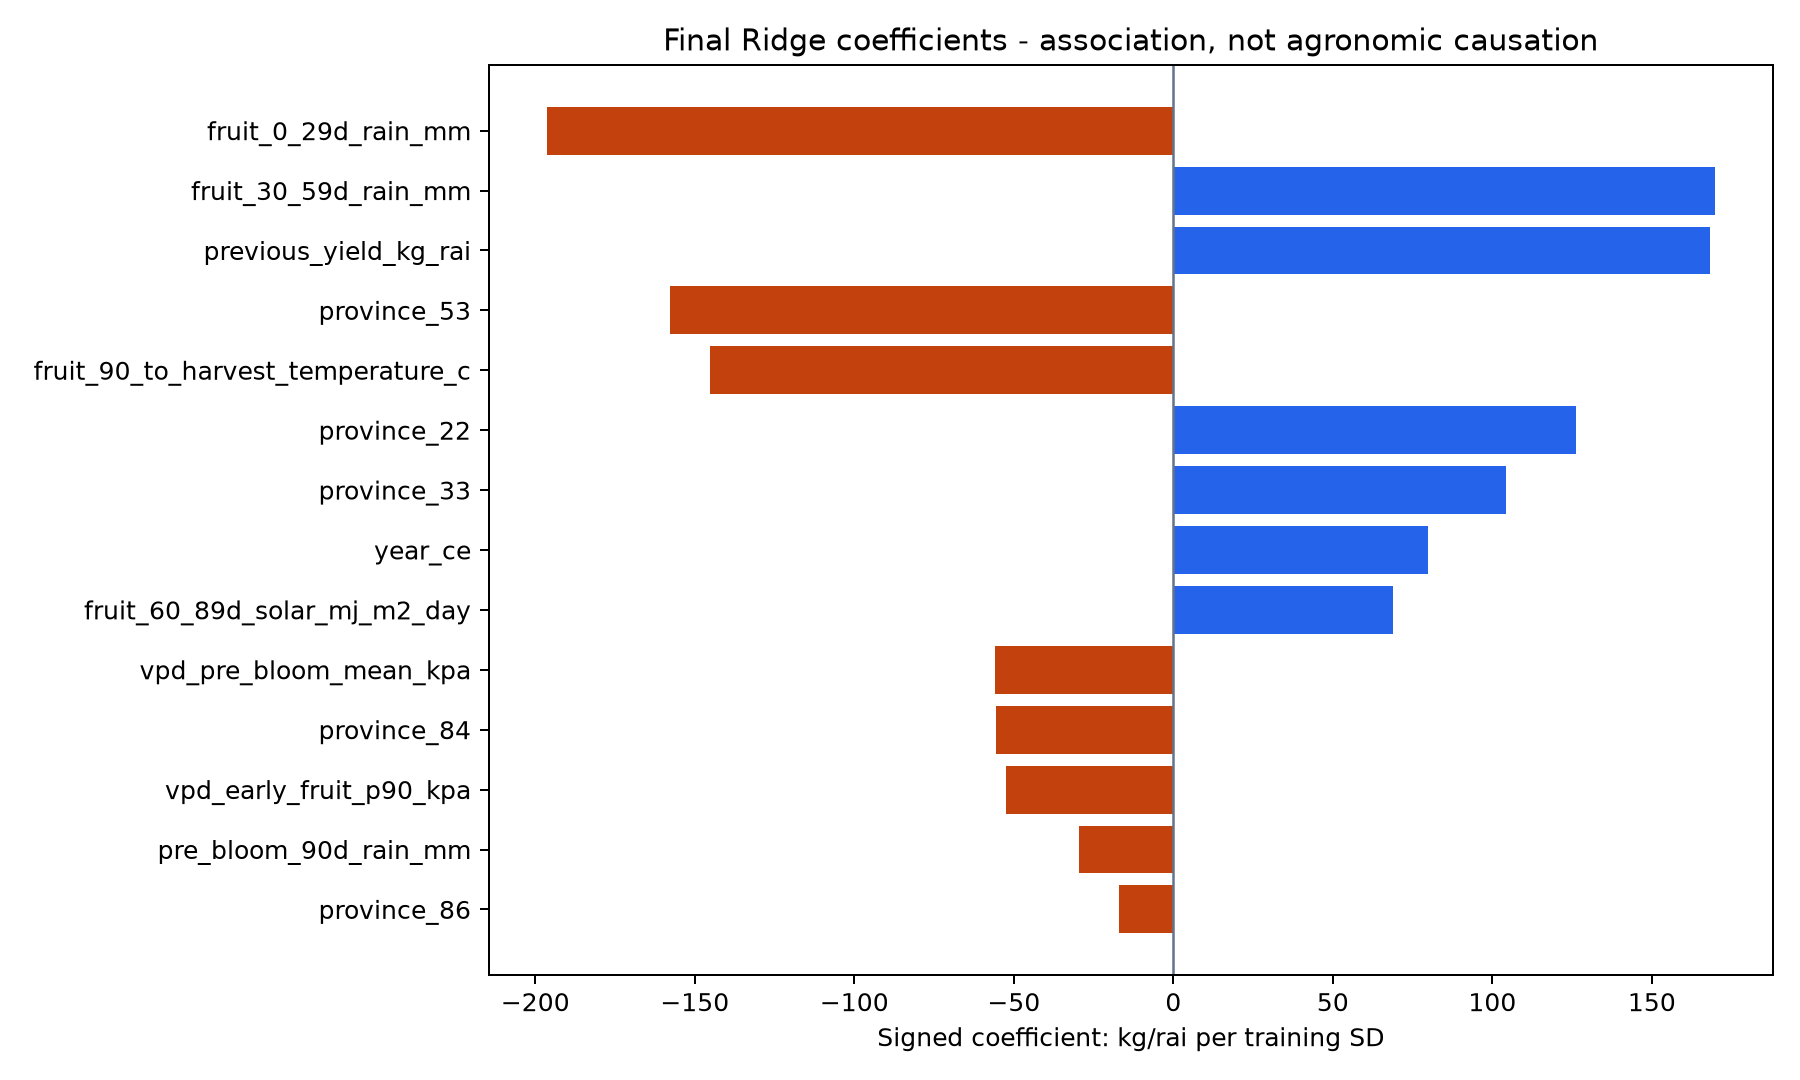

In [6]:
import step4_investigate_feature_importance
result_4 = step4_investigate_feature_importance.run()
display(result_4)
display(Image(filename=str(OUT / 'ridge_vpd_coefficients.png')))

## ขั้น 5: step5_evaluate_result
ประเมิน rolling-origin test predictions และ paired year-block bootstrap เชิงพรรณนา

Step 5: {"n": 45, "mae_kg_rai": 190.86763624512602, "rmse_kg_rai": 243.42358147495688, "bias_kg_rai": -27.264035891158134} benchmark reproduced: True


,n,mae_kg_rai,rmse_kg_rai,bias_kg_rai
Ridge + VPD,45,190.867636,243.423581,-27.264036
Previous year,45,215.511937,269.547693,-44.409617


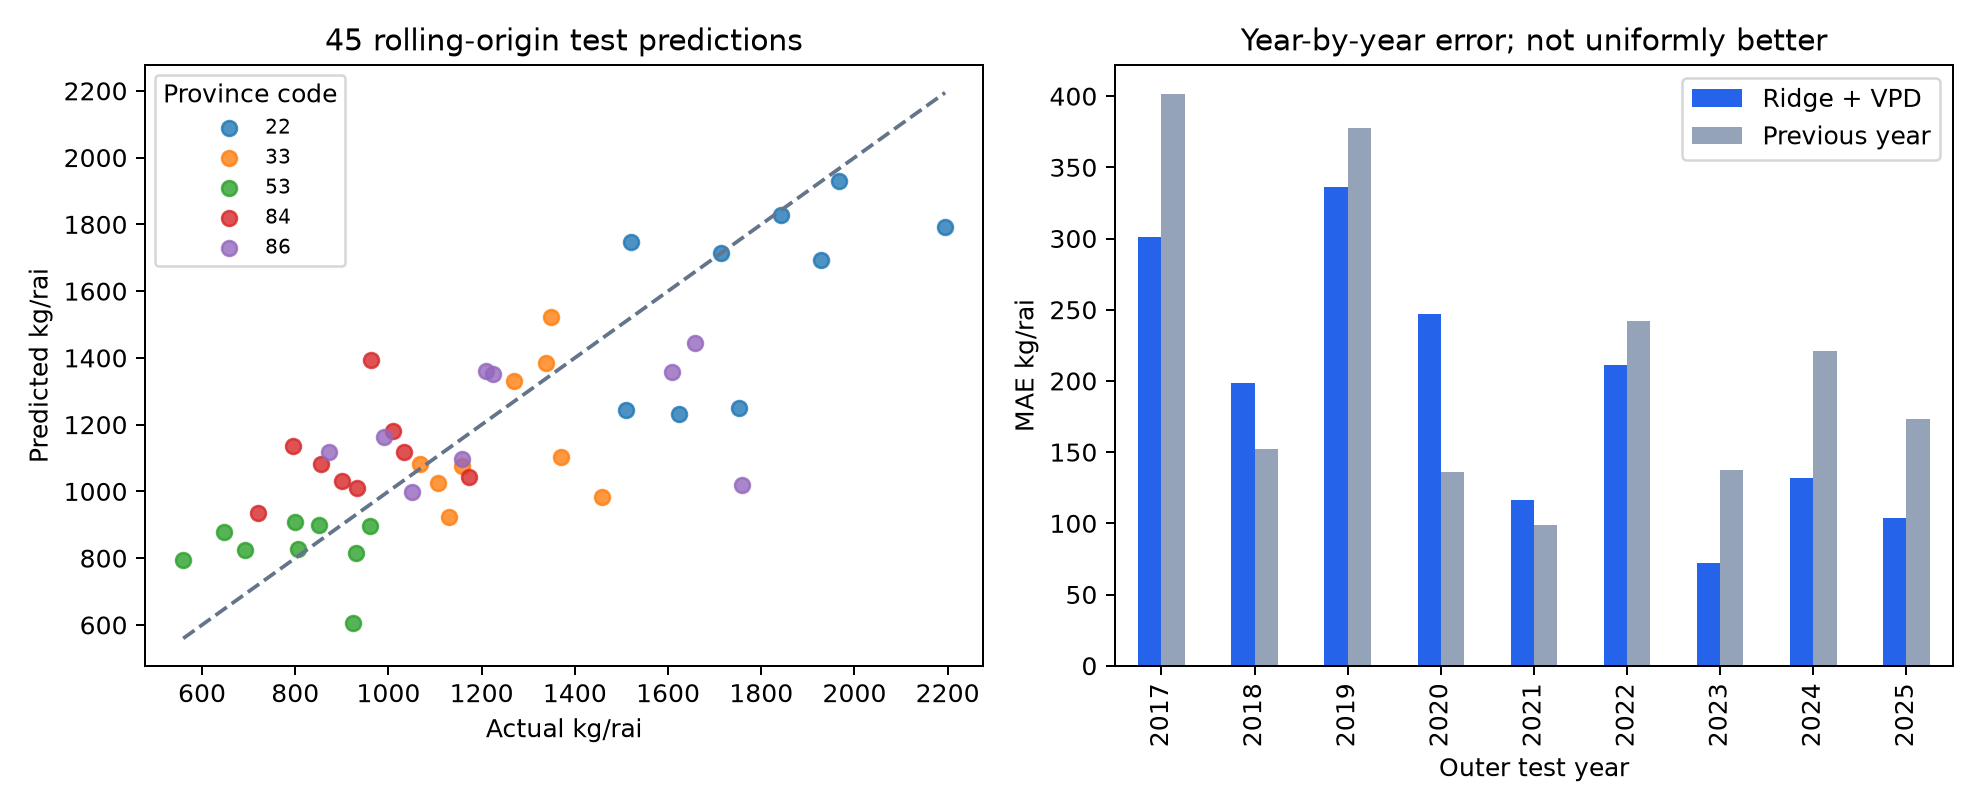

,comparator,method,block_length_years,resamples,seed,n_years,n_rows,mae_gain_kg_rai,mae_reduction_pct,gain_percentile_95_kg_rai,reduction_percentile_95_pct,worse_years
0,previous_year,paired circular year-block bootstrap,3,20000,42,9,45,24.644301,11.435237,"[-32.23891608168984, 71.2908254651382]","[-16.411246042501638, 34.096497337111764]","[2018, 2020, 2021]"
1,previous_year,paired circular year-block bootstrap,2,20000,42,9,45,24.644301,11.435237,"[-22.940817383648493, 67.71816928970185]","[-12.248359146255904, 31.08685184474771]","[2018, 2020, 2021]"
2,stage_ridge,paired circular year-block bootstrap,3,20000,42,9,45,4.025011,2.065245,"[-6.37613024752693, 16.51823301674162]","[-3.576928375264643, 8.285086329788582]","[2019, 2020, 2021, 2022]"
3,stage_ridge,paired circular year-block bootstrap,2,20000,42,9,45,4.025011,2.065245,"[-5.587946320150963, 14.796186932385496]","[-3.086407165117066, 7.378485742886188]","[2019, 2020, 2021, 2022]"


Descriptive percentile ranges conditional on fixed predictions; only nine year clusters, five fixed provinces, unverified stationarity and circular boundary. Block lengths 3 and 2 retain only short serial dependence. No model refitting or correction for 26-method selection optimism; not confirmatory confidence intervals or operational prediction intervals.


In [7]:
import step5_evaluate_result
result_5 = step5_evaluate_result.run()
display(pd.DataFrame([result_5['overall'], result_5['previous_year']], index=['Ridge + VPD', 'Previous year']))
display(Image(filename=str(OUT / 'ridge_vpd_evaluation.png')))
display(pd.DataFrame([dict(comparator=name, **estimate) for name, estimates in result_5['paired_uncertainty'].items() for estimate in estimates]))
print(result_5['uncertainty_warning'])

## ขั้น 6: step6_predict_live
demo 2025 ใช้โมเดล train ถึง 2024; ยังไม่เชื่อม API พยากรณ์สด

In [8]:
import step6_predict_live
result_6 = step6_predict_live.run()
display(result_6)

Step 6: conditional predictions, not validated live forecasts.
 province_code  year_ce  predicted_kg_rai
           22     2025       1712.981034
           33     2025       1101.675052
           53     2025        816.114290
           84     2025       1009.030886
           86     2025       1097.170980


,province_code,year_ce,predicted_kg_rai
3695,22,2025,1712.981034
3711,33,2025,1101.675052
3727,53,2025,816.114290
3743,84,2025,1009.030886
3759,86,2025,1097.170980
